# A/B-тест подсказки при бронировании

## tl;dr

**Решение: LAUNCH с постепенным rollout.** В зафиксированной synthetic
реализации treatment увеличивает conversion с 40.64% до 43.44%:
+2.80 п.п. (95% CI +2.01…+3.59 п.п.; Holm p < 0.001). Это выше MDE
1.13 п.п. и продуктового порога +0.7 п.п. Cancellation и time-to-book
проходят предзаданные non-inferiority маржи. Ниже — воспроизводимый
путь от событий к этому решению.

## Context & Methods

**Решение:** запускать ли новую подсказку на экране бронирования.

**Primary:** conversion to booking в течение 24 часов после первого экрана.
**Guardrails:** cancellation rate в 24 часа после бронирования и time-to-book.
**Дизайн:** user-level 50:50 A/B, ITT-анализ, Holm для семьи из primary и
двух guardrails. Синтетические данные не относятся к реальному каршерингу.

### Key Assumptions

Когорта состоит из eligible пользователей с созревшим 24-часовым окном;
сегменты заданы до treatment и не применяются для смены решения.

## Data

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.run_analysis import build_mart, calculate_results, load_sources, quality_checks

DATA_DIR = ROOT / "data" / "generated"
SQL_FILE = ROOT / "sql" / "experiment_mart.sql"
users, assignments, events = load_sources(DATA_DIR)
users.head()

,user_id,platform,city,is_new_user,trips_30d,acquisition_channel,trips_30d_bucket
0,u_000001,iOS,St_Petersburg,1,10,organic,8+
1,u_000002,iOS,Moscow,1,4,organic,4-7
2,u_000003,Android,Moscow,0,5,paid,4-7
3,u_000004,iOS,Moscow,0,6,referral,4-7
4,u_000005,Android,Kazan,0,5,organic,4-7


In [2]:
# pandas filter + merge: проверить покрытие событий назначениями.
post_assignment_events = events.merge(
    assignments[["user_id", "assigned_at", "variant"]],
    on="user_id", how="left", validate="many_to_one"
).query("event_ts >= assigned_at")
post_assignment_events.groupby(["variant", "event_name"], observed=True).size().unstack(fill_value=0)

event_name,booking_cancelled,booking_created,booking_hint_shown,booking_screen_view
variant,,,,
control,1074,12133,0,29854
treatment,1177,13096,29072,30146


## Results

In [3]:
# SQL builds a one-row-per-user mart with CTEs, joins and window functions.
mart = build_mart(DATA_DIR, SQL_FILE)
checks = quality_checks(users, assignments, events, mart)
pd.DataFrame(checks)

,check,value,expected,status
0,Одна запись назначения на пользователя,0,0,pass
1,Пересечение вариантов по пользователю,0,0,pass
2,Дубликаты event_id,0,0,pass
3,Полные дубликаты событий,0,0,pass
4,События без назначения,0,0,pass
5,События до назначения,0,0,pass
6,Показ подсказки в control,0,0,pass
7,Покрытие пользователей при JOIN assignments → ...,0,0,pass
8,Дубликаты user_id в SQL-витрине,0,0,pass
9,Потеря пользователей между assignment и mature...,0,0,pass


In [4]:
# pandas groupby makes the ITT denominators visible before inferential tests.
mart.groupby("variant", observed=True).agg(
    users=("user_id", "nunique"),
    conversion=("booked", "mean"),
    cancellation=("cancelled_24h", "mean"),
    median_time_to_book=("time_to_book_seconds", "median"),
)

,users,conversion,cancellation,median_time_to_book
variant,,,,
control,29854,0.406411,0.035975,162.0
treatment,30146,0.434419,0.039043,164.0


In [5]:
results, segment_results = calculate_results(mart)
print(json.dumps(results, ensure_ascii=False, indent=2))
segment_results

{
  "sample_ratio_mismatch": {
    "control_n": 29854,
    "treatment_n": 30146,
    "expected_per_variant": 30000.0,
    "chi_square": 1.4210666666666667,
    "p_value": 0.23322791476062285
  },
  "variant_summary": [
    {
      "variant": "control",
      "users": 29854,
      "exposed": 0.0,
      "bookings": 12133,
      "conversion": 0.4064112011790715
    },
    {
      "variant": "treatment",
      "users": 30146,
      "exposed": 0.9643733828700325,
      "bookings": 13096,
      "conversion": 0.4344191600875738
    }
  ],
  "primary_conversion": {
    "control_n": 29854,
    "treatment_n": 30146,
    "control_rate": 0.4064112011790715,
    "treatment_rate": 0.4344191600875738,
    "difference": 0.02800795890850233,
    "ci_low": 0.02011171078668287,
    "ci_high": 0.03590420703032179,
    "z_stat": 6.948876425865563,
    "p_value": 1.8410344583288065e-12,
    "p_value_holm": 3.682068916657613e-12
  },
  "guardrail_cancellation": {
    "control_n": 12133,
    "treatment_n": 13

,segment,level,control_n,treatment_n,control_conversion,treatment_conversion,difference_pp,ci_low_pp,ci_high_pp,p_value,p_value_holm
0,city,Kazan,4737,4798,0.392654,0.423301,3.064780,1.092873,5.036687,1.165301e-03,5.826505e-03
1,city,Moscow,14338,14491,0.419375,0.452143,3.276762,2.132626,4.420899,1.011981e-08,1.214377e-07
2,city,St_Petersburg,7192,7120,0.396830,0.419663,2.283311,0.673194,3.893428,2.727989e-03,1.091196e-02
3,city,Yekaterinburg,3587,3737,0.391971,0.408081,1.611034,-0.632935,3.855003,7.975041e-02,1.595008e-01
4,is_new_user,0,17350,17623,0.392046,0.416558,2.451180,1.422835,3.479525,1.506079e-06,1.204863e-05
5,is_new_user,1,12504,12523,0.426344,0.459554,3.321085,2.090946,4.551224,6.167755e-08,6.784531e-07
6,platform,Android,16142,16310,0.396543,0.425199,2.865608,1.795507,3.935710,7.769986e-08,7.262745e-07
7,platform,iOS,13712,13836,0.418028,0.445288,2.725965,1.556626,3.895304,2.471569e-06,1.730099e-05
8,trips_30d_bucket,0,585,615,0.362393,0.413008,5.061497,-0.444505,10.567499,3.607066e-02,1.082120e-01
9,trips_30d_bucket,1-3,12266,12399,0.391000,0.423905,3.290564,2.064861,4.516268,7.262745e-08,7.262745e-07


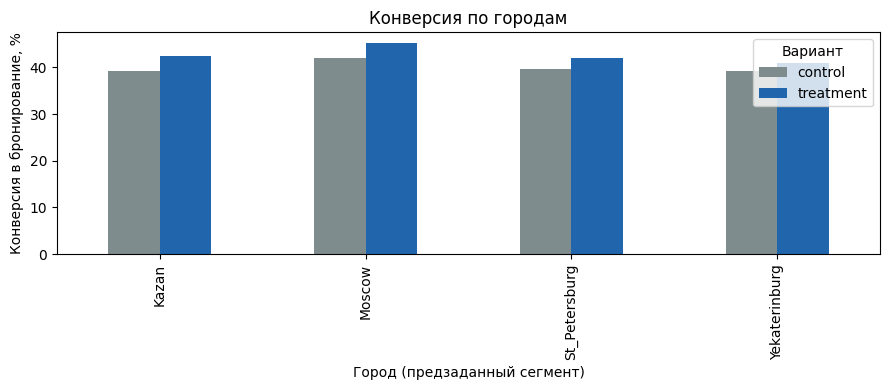

In [6]:
city_rates = mart.groupby(["city", "variant"], observed=True)["booked"].mean().unstack()
ax = (city_rates * 100).plot(kind="bar", figsize=(9, 4), color=["#7f8c8d", "#2166ac"])
ax.set_ylabel("Конверсия в бронирование, %")
ax.set_xlabel("Город (предзаданный сегмент)")
ax.set_title("Конверсия по городам")
ax.legend(title="Вариант")
plt.tight_layout()
plt.show()

## Takeaways

Посмотрите `reports/analysis_report.md` для итогового решения и `reports/analysis_results.json`
для машиночитаемых оценок. Launch разрешён только если Holm-скорректированный
primary-тест положителен и оба guardrail non-inferiority теста пройдены.